In [27]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import matplotlib as mpl
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq, minimize_scalar
import numpy.ma as ma
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator
from astropy.time import Time
from typing import Union, List
from scipy.signal import find_peaks
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

import frb_functions

from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as ticker

In [28]:
def masked_percentile(arr, q):
    return np.percentile(arr.compressed(), q)

In [29]:
def load_burst_wb(burst,burst_tstamp, downsamp_t=1,downsamp_f=1):

    print("#############")
    print("## Loading Westerbork ##")
    print("#############")
    
    burst = your.Your(burst)

    header_dict = frb_functions.your_header_to_dict(burst)
    tsamp = header_dict["tsamp"]
    nbins = header_dict["nspectra"]
    fsamp = header_dict["foff"] * -1
    freqs = header_dict["freqs"] # in Mhz
    
    tmin = 0.0
    tmax = nbins * burst.tsamp # seconds
    fmin = header_dict["fmin"]
    fmax = header_dict["fmax"]
    extent_b = [tmin, tmax, fmin, fmax]

    offset = burst_tstamp #
    extent_b[0] = (tmin - offset) * 1000
    extent_b[1] = (tmax - offset) * 1000
    print(f"the extent of the data is: {extent_b}")
    
    #time increasing, freq decreasing
    print("loading in the data")
    d = frb_functions.get_data(burst, nstart=0, nsamp=nbins, npoln=1)

    sides_bandpass = 'right' 
    scale_bandpass = 3

    #Correcting the bandpass
    stokes_i = frb_functions.correct_bandpass(d, sides=sides_bandpass, scale=scale_bandpass)

    #Masking the subband edges en correcting for the bandpass again
    bandwidth = header_dict["bw"] * - 1
    nchans = header_dict["nchans"]
    band_edges = frb_functions.get_subband_edges(bandwidth, nchans)
    stokes_i = frb_functions.mask_array(array=stokes_i, bad_chan_idx=band_edges)

    #Correcting the bandpass
    stokes_i = frb_functions.correct_bandpass(stokes_i, sides=sides_bandpass, scale=scale_bandpass)
    
    print(f"downsample factors are: time:{downsamp_t} and freq:{downsamp_f}")
    if downsamp_f > 1 or downsamp_t > 1:
        print(f"running downsampling and correcting bandpass")
        stokes_i = frb_functions.downsample(stokes_i, freqf=downsamp_f, timef=downsamp_t)
        tsamp = tsamp * downsamp_t
        fsamp = fsamp * downsamp_f
        stokes_i = frb_functions.correct_bandpass(stokes_i, sides=sides_bandpass, scale=scale_bandpass)
        downsamp_flag = True
    else:
        downsamp_flag = False

    #Create x grid to plot the step function. 
    x_grid = np.linspace(extent_b[0], extent_b[1], endpoint=False, num=stokes_i.shape[1])

    prof = np.ma.mean(stokes_i,axis=0)
    stokes_i_normprof = frb_functions.normalize_1d(prof, sides=sides_bandpass, scale=scale_bandpass)

    new_quantiles = masked_percentile(stokes_i, (0.01, 99.99))
    #new_quantiles = np.nanpercentile(stokes_i, (0.01, 99.99))

    return stokes_i, stokes_i_normprof, x_grid, new_quantiles, extent_b, tsamp, fsamp

In [30]:
def load_burst_nrt(DM, burst_name):

    print("#############")
    print("## Loading NRT ##")
    print("#############")
    ###################################
    burst = your.Your(burst_name)

    header_dict = frb_functions.your_header_to_dict(burst)
    tsamp = header_dict["tsamp"]
    nbins = header_dict["nspectra"]
    fsamp = header_dict["foff"] 
    
    tmin = 0.0
    tmax = nbins * burst.tsamp # seconds
    fmin = header_dict["fmin"]
    fmax = header_dict["fmax"]
    extent_b = [tmin, tmax, fmin, fmax]

    offset = 0.119 #seconds -bin = int(0.119/16e-6) 
    extent_b[0] = (tmin - offset) * 1000
    extent_b[1] = (tmax - offset) * 1000
    print(f"the extent of the data is: {extent_b}")
    
    #time increasing, freq decreasing
    print("loading in the data")
    full_pol_data = frb_functions.get_data(burst, nstart=0, nsamp=nbins, npoln=4)

    sides_bandpass = 'right' 
    scale_bandpass = 3
    #get coherence products    
    aa = full_pol_data["AA"]
    aa_norm = frb_functions.correct_bandpass(aa, sides=sides_bandpass, scale=scale_bandpass)
    
    bb = full_pol_data["BB"]
    bb_norm = frb_functions.correct_bandpass(bb, sides=sides_bandpass, scale=scale_bandpass)  
    
    #make stokesi 
    d = aa_norm + bb_norm
    d = frb_functions.correct_bandpass(d, sides=sides_bandpass, scale=scale_bandpass)
    
    freqs = header_dict["freqs"] # in Mhz
       
    dm_dedisp = DM
    print(f"de-dispersing to {dm_dedisp} pc/cc")
    stokes_i = frb_functions.dedisperse(d,dm_dedisp,freqs,tsamp)

    print(f"Masking channels")
    mask_arr = frb_functions.extract_numbers_pazi(input_string='paz -z "49 45 46 30 28 15 16 127 126 125 123 122 121 102 103 93" -e pazi B01-NRT.fil.ar',\
                                                 total_channels=128, map_channels=True)
    print(mask_arr)
    stokes_i = frb_functions.mask_array(array=stokes_i, bad_chan_idx=mask_arr)

    print(f"Correcting for the bandpass")
    stokes_i = frb_functions.correct_bandpass(stokes_i, sides=sides_bandpass, scale=scale_bandpass)

    downsamp_t = 1
    downsamp_f = 1
    print(f"downsample factors are: time:{downsamp_t} and freq:{downsamp_f}")
    if downsamp_f > 1 or downsamp_t > 1:
        print(f"running downsampling and correcting bandpass")
        stokes_i = frb_functions.downsample(stokes_i, freqf=downsamp_f, timef=downsamp_t)
        tsamp = tsamp * downsamp_t
        fsamp = fsamp * downsamp_f
        stokes_i = frb_functions.correct_bandpass(stokes_i, sides=sides_bandpass, scale=scale_bandpass)
        downsamp_flag = True
    else:
        downsamp_flag = False

    #Create x grid to plot the step function. 
    x_grid = np.linspace(extent_b[0], extent_b[1], endpoint=False, num=stokes_i.shape[1])

    prof = np.ma.mean(stokes_i,axis=0)
    stokes_i_normprof = frb_functions.normalize_1d(prof, sides=sides_bandpass, scale=scale_bandpass)

    new_quantiles = np.nanpercentile(stokes_i, (1.0, 99.99))
    
    return stokes_i, stokes_i_normprof, x_grid, new_quantiles, extent_b

#############
## Loading NRT ##
#############
the extent of the data is: [-119.0, 2881.0, 1228.0, 1740.0]
loading in the data
de-dispersing to 464.863 pc/cc
Masking channels
[ 78  82  81  97  99 112 111   0   1   2   4   5   6  25  24  34]
Correcting for the bandpass
downsample factors are: time:1 and freq:1


/usr/local/anaconda/lib/python3.11/site-packages/numpy/lib/function_base.py:4737: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


#############
## Loading Westerbork ##
#############
the extent of the data is: [-339.8, 1452.2, 1207.0, 1335.0]
loading in the data
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32
downsample factors are: time:16 and freq:1
running downsampling and correcting bandpass
#############
## Making Plot ##
#############


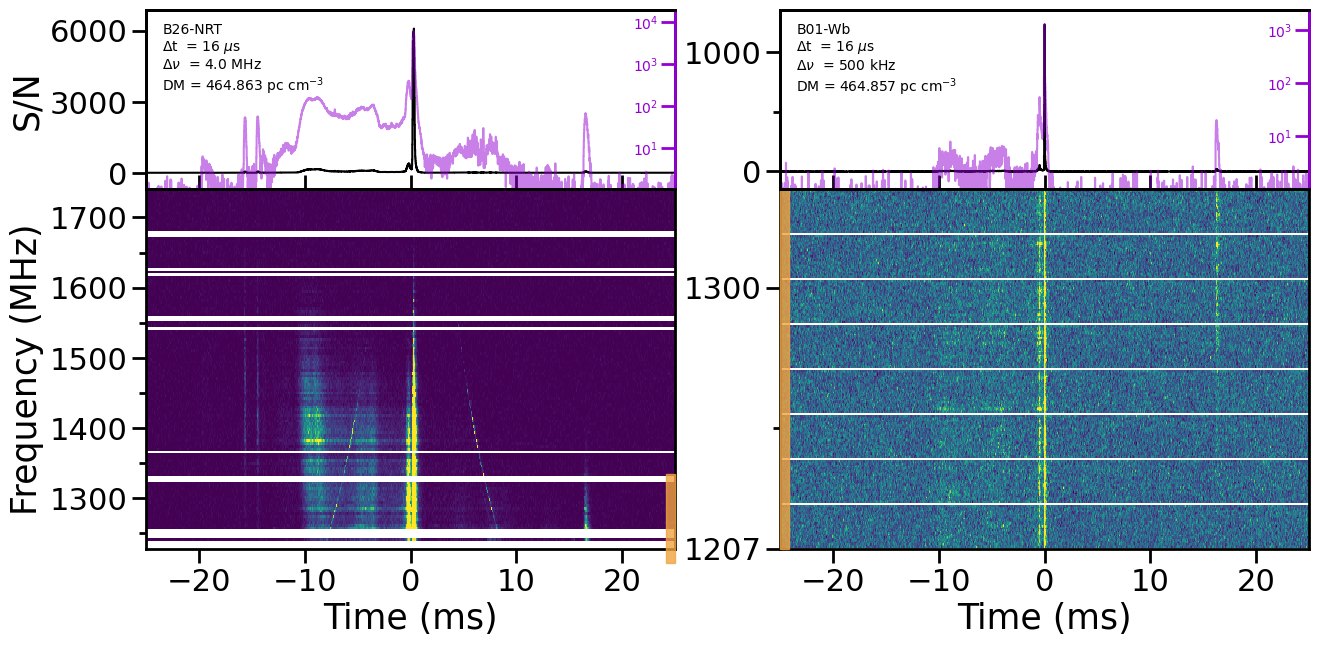

In [38]:
def waterfaller_dm():
    """
    NRT WB
    ax1 ax2 -- time series
    ax3 ax4 -- dynamic spectra   
    """
    
    ###################################
    #Loading in the burst
    burst_dat = "/scratch1/baseband_extractions/frb240619D_meerkat/nancay/burst_60511.98777606648s3p3t119.15.fil"
    
    ##### NRT ######
    #DM -- 464.863 
    stokes_i, stokes_i_normprof, x_grid, new_quantiles, extent = load_burst_nrt(DM=464.863, burst_name=burst_dat)

    ##### WB  ######
    #DM -- 465.534 

    wb_burst = "/data1/omar/sfxc/frb240619d/p55025_28/p55025_28_1us_500KHz_StokesI_DM464857.cor_Wb.fil"
    wb_burst_tstamp = 0.3398
    
    stokes_i_wb, stokes_i_normprof_wb, x_grid_wb, new_quantiles_wb, extent_b_wb, tsamp_wb, fsamp_wb = load_burst_wb(burst = wb_burst,\
                                                                                                      burst_tstamp = wb_burst_tstamp,\
                                                                                                      downsamp_t=16, downsamp_f=1)

    print("#############")
    print("## Making Plot ##")
    print("#############")    
    ###################################
    #Define the figure
    fig5 = plt.figure(figsize=(15,7))
    
    #Width 0.1 is for the hidden axes
    widths = [1, 1]
    heights = [1, 2]
    spec5 = fig5.add_gridspec(ncols=2, nrows=2, width_ratios=widths, height_ratios=heights, wspace=0.2, hspace=0.0)

    ###################################
    #Drawing the dynamic spectra
    #ax3
    ax3 = fig5.add_subplot(spec5[1, 0])
    ax3.imshow(stokes_i, aspect='auto', interpolation='None', origin='lower',\
          extent=extent, vmin=new_quantiles[0], vmax=new_quantiles[1])
    window_ms = 25
    ax3.set_xlim(-window_ms,window_ms)
    ax3.set_ylabel('Frequency (MHz)',size=25)
    ax3.set_xlabel('Time (ms)',size=25)

    ax3.xaxis.set_minor_locator(ticker.MultipleLocator(10))
    majors = [1300,1400,1500,1600,1700]
    minors = [1250,1350,1450,1550,1650,1750]
    ax3.yaxis.set_major_locator(ticker.FixedLocator(majors))
    ax3.yaxis.set_minor_locator(ticker.FixedLocator(minors))

    #ax4
    ax4 = fig5.add_subplot(spec5[1, 1])
    ax4.set_xlabel('Time (ms)',size=25)
    ax4.imshow(stokes_i_wb, aspect='auto', interpolation='None', origin='lower',\
          extent=extent_b_wb, vmin=new_quantiles_wb[0], vmax=new_quantiles_wb[1])
    window_ms = 25
    ax4.set_xlim(-window_ms,window_ms)

    majors = [1207,1300]
    minors = [1250]
    ax4.yaxis.set_major_locator(ticker.FixedLocator(majors))
    ax4.yaxis.set_minor_locator(ticker.FixedLocator(minors))
    ax4.set_yticks([1300, 1207], ["1300", "1207"])  # Set tick positions in MHz 

    # x-coordinate: start from the leftmost point of ax3
    # Width of the patch in time (ms)
    width_patch = 0.8
    freq_min_p = 1207
    freq_max_p = 1335        
    x0_patch = ax3.get_xlim()[0]  # left edge of the current x-axis
    x0_patch_right = ax3.get_xlim()[1] - width_patch
    
    # Add the patch
    ax3.add_patch(Rectangle((x0_patch_right, freq_min_p), width_patch, freq_max_p - freq_min_p, color='#f1a340', \
                            alpha=0.8, zorder=5, clip_on=False))
    ax4.add_patch(Rectangle((x0_patch, freq_min_p), width_patch, freq_max_p - freq_min_p, color='#f1a340', \
                            alpha=0.8, zorder=5, clip_on=False))
    
    # ax4.xaxis.set_minor_locator(ticker.MultipleLocator(10))
    # ax4.set_yticks([1300, 1207], ["", ""])  # Convert to GHz
    # ax4.set_yticks([1300, 1207], ["1300", "1200"])  # Set tick positions in MHz 
    # ax4.yaxis.set_minor_locator(ticker.FixedLocator([1250]))

    # majors = [1300]
    # minors = [1250]
    # ax4.yaxis.set_major_locator(ticker.FixedLocator(majors))
    # ax4.yaxis.set_minor_locator(ticker.FixedLocator(minors))

    ###################################
    #Drawing the time series
    #ax1
    ax1 = fig5.add_subplot(spec5[0, 0], sharex=ax3)
    ax1.set_ylabel('S/N',size=25)
    
    ax1.plot(x_grid, stokes_i_normprof, drawstyle='steps-post', color='black') 
    maxSN = np.ceil(np.max(stokes_i_normprof))
    yticks_sn=np.array([0, round(int(maxSN/2), -3), round(int(maxSN), -3)])
    ax1.set_yticks(yticks_sn)
    ax1.set_ylim(-700,maxSN+800)
    DM_value_nrt = 464.863
    #    ax1.text(0.04, 0.93, fr"$\Delta$t  = {(tsamp*1e6):.0f} $\mu$s" + "\n" + fr"$\Delta \nu$  = {(fsamp*1e3):.0f} kHz " + "\n" + \
    #         fr"DM = {DM:.1f}"+ r" pc cm$^{-3}$", transform=ax1.transAxes, fontsize=19, va='top', ha='left')
    ax1.text(0.03, 0.93, "B26-NRT" + "\n" + fr"$\Delta$t  = 16 $\mu$s" + "\n" + fr"$\Delta \nu$  = 4.0 MHz " + "\n" + \
              fr"DM = {DM_value_nrt:.3f}" + r" pc cm$^{-3}$", transform=ax1.transAxes, fontsize=10, va='top', ha='left')
    
    #log profile
    ax1_twin=ax1.twinx()
    ax1_twin.step(x_grid, stokes_i_normprof, drawstyle='steps-post', color='darkviolet', where='mid', alpha=0.5)
    ax1_twin.set_yscale('log')
    ax1_twin.set_ylim(1,20_000)
    yticks_sn_log=np.array([])
    ax1_twin.set_yticks(yticks_sn_log)
    #ax1.set_title(fr"DM = {464.863:.3f}" + " $\pm$ " + f"{0.029}" + r" pc cm$^{-3}$", fontsize=22, pad=10)

    #ax2
    ax2 = fig5.add_subplot(spec5[0, 1], sharex=ax4)
    ax2.plot(x_grid_wb, stokes_i_normprof_wb, drawstyle='steps-post', color='black')

    maxSN = np.max(stokes_i_normprof_wb)
    window_sn = 1.1 * maxSN
    minSN = -150
    yticks_sn=np.array([0, round(int(maxSN), -3)])
    ax2.yaxis.set_minor_locator(ticker.FixedLocator([500]))
    ax2.set_yticks(yticks_sn)
    ax2.set_ylim(minSN,window_sn)
    DM_value_wb = 464.857
    ax2.text(0.03, 0.93, "B01-Wb" + "\n" + fr"$\Delta$t  = {(tsamp_wb*1e6):.0f} $\mu$s" + "\n" + \
              fr"$\Delta \nu$  = {(fsamp_wb*1e3):.0f} kHz " + "\n" + \
              fr"DM = {DM_value_wb:.3f}" + r" pc cm$^{-3}$", transform=ax2.transAxes, fontsize=10, va='top', ha='left')
    
    ax2_twin=ax2.twinx()
    ax2_twin.step(x_grid_wb, stokes_i_normprof_wb, drawstyle='steps-post', color='darkviolet', where='mid', alpha=0.5)
    ax2_twin.set_yscale('log')
    ax2_twin.set_ylim(1,window_sn+1000)
    yticks_sn_log=np.array([])
    ax2_twin.set_yticks(yticks_sn_log)
    
    #ax2.set_ylim(-700,maxSN_sc+800)
    #ax2.set_title(fr"DM = {465.54:.3f}" + " $\pm$ " + f"{0.028}" + r" pc cm$^{-3}$", fontsize=22, pad=10)  
    
    ###################################
    #Settings for the plot
    for ax in [ax1,ax2,ax3,ax4,ax1_twin,ax2_twin]:
        
        ax.tick_params(labelsize=22) 
        
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
    
    for ax in [ax1, ax2]:
        
        ax.tick_params(labelbottom=False)
        ax.tick_params(axis='x', which='major', direction='in', length=10, width=2)
        ax.tick_params(axis='x', which='minor', direction='in', length=5, width=2)

    # Style inward ticks for the log axis -- Define ticks per axis
    log_color = "darkviolet"
    ticks_dict = {
        ax1_twin: [10, 100, 1000, 10_000], 
        ax2_twin: [10, 100, 1000]
    }
    
    for ax_twin, ticks in ticks_dict.items():
        
        ax_twin.set_yscale("log")
        
        # Keep only ticks within current axis limits
        ymin, ymax = ax_twin.get_ylim()
        ticks = [t for t in ticks if ymin < t < ymax]
        
        # Apply ticks
        ax_twin.set_yticks(ticks)
        ax_twin.yaxis.set_minor_locator(ticker.NullLocator())
        
        # Style ticks inward, colored
        ax_twin.tick_params(axis='y', which='major', direction='in', length=10, width=2, colors=log_color, labelright=True, labelleft=False,\
                           pad=-30, labelsize=10)
        
        # Color right spine
        ax_twin.spines["right"].set_color(log_color)

    ###################################
    #Saving the plot
    plot_name = "wb_nrt_plot_V2"

    plt.show()
    fig5.savefig(f"../plots/{plot_name}" + ".pdf", dpi=300, bbox_inches='tight')
    
    fig5.savefig(f"../plots/{plot_name}" + ".png", facecolor='white', \
           transparent=False, format = 'png',bbox_inches='tight', dpi=300)
    
    return

waterfaller_dm()